# Exploratory Data Analysis

Purchase occasions of *Everything & Then Some*. For each purchase we want to know whether the customer
buys again within 90 days, and how much they spend in that period.

The raw profile of every column (shapes, missing values, unique counts, test-only levels) is in
`docs/data_notes.md` and is not repeated here. This notebook looks at the data only: nothing is
transformed or cleaned yet.

| Section | Content |
|---|---|
| 1 | Targets |

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent              # the notebook runs from notebooks/
sys.path.append(str(ROOT))

from main import load_config
from src.data import load_raw

cfg = load_config()
train = load_raw(cfg, "train_file")

CLS = cfg["data"]["targets"]["classification"]
REG = cfg["data"]["targets"]["regression"]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.dpi": 110})
COLOR = "#3b6ea5"
train.shape

(6534, 40)

In [16]:
CLS, REG

('repeat_purchase_90d', 'spend_next_90d')

In [13]:
from pprint import pprint

print("cfg =")
pprint(cfg, sort_dicts=False)
print("\nCLS =", repr(CLS))
print("REG =", repr(REG))
print("\ntrain =")
train

cfg =
{'seed': 42,
 'data': {'dir': 'data/raw',
          'train_file': 'train.csv',
          'test_file': 'test.csv',
          'clientes_file': 'clientes.csv',
          'sample_submission_file': 'sample_submission.csv',
          'id_column': 'ID',
          'group_column': 'customer_id',
          'date_column': 'purchase_date',
          'targets': {'classification': 'repeat_purchase_90d',
                      'regression': 'spend_next_90d'},
          'clientes_columns': []},
 'cleaning': {'float_columns': ['N_ Detalhes',
                                'invoice_count_current_purchase',
                                'customer_tenure_days',
                                'prior_purchase_count',
                                'purchase_count_30d',
                                'purchase_count_90d',
                                'purchase_count_180d',
                                'purchase_count_365d']},
 'features': {'numeric': ['Total a Pagar',
                       

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.00,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.00,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.00,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.00,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.00,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6529,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49.0,1.0,...,151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,10007670,-1.579719
6530,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16.0,1.0,...,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,10007671,-0.576883
6531,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78.0,1.0,...,755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,10007672,0.528377
6532,452.07,483.60,367.54,84.53,0.0,0.00,116.06,265.159468,7.0,1.0,...,703834,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2019-03-23,10007673,1.012809


`cfg` is the full content of `config.yaml` as a nested dictionary. `CLS` and `REG` are
strings which we took from `cfg["data"]["targets"]`, with the names of the two target columns. `train` is the
raw `train.csv` as a DataFrame, and `train[CLS]` / `train[REG]` select its target columns.


## 1. Targets

Our two targets (ONLY in `train.csv` !!):

- `repeat_purchase_90d`: 1 if the customer buys again within 90 days (classification)
- `spend_next_90d`: how much they spend in those 90 days (numerical/regression)

### 1.1 Classification target

In [2]:
counts = train[CLS].value_counts()
pd.DataFrame({"rows": counts, "share": (counts / len(train)).round(3)})

,rows,share
repeat_purchase_90d,,
1,3654,0.559
0,2880,0.441


Share is the proportion of each class in the dataset.

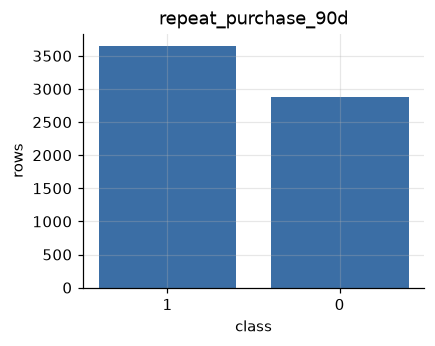

In [3]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(counts.index.astype(str), counts.values, color=COLOR)
ax.set(title="repeat_purchase_90d", xlabel="class", ylabel="rows")
plt.show()

The classes are rather balanced: about 56% of purchases are followed by another one within 90 days

### 1.2 Positive rate over time

Is the share of returning customers stable across the years?

In [4]:
year = pd.to_datetime(train["purchase_date"]).dt.year
by_year = train.groupby(year)[CLS].agg(rows="size", positive_rate="mean").round(3)
by_year.index = by_year.index.astype(int)
by_year.T

purchase_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rows,335.000,420.000,670.000,716.000,646.000,670.000,782.000,628.000,767.000,757.000,78.000
positive_rate,0.534,0.514,0.633,0.538,0.522,0.594,0.549,0.481,0.581,0.602,0.628


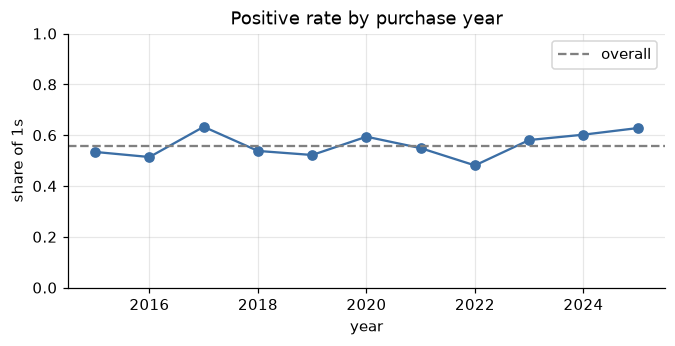

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_year.index, by_year["positive_rate"], marker="o", color=COLOR)
ax.axhline(train[CLS].mean(), color="grey", linestyle="--", label="overall")
ax.set(title="Positive rate by purchase year", xlabel="year", ylabel="share of 1s", ylim=(0, 1))
ax.legend()
plt.show()

The rate moves between 0.48 and 0.63 with no clear trend. 2025 has only 78 rows, so its rate is less
reliable. The 65 rows without a date are not in the table.

### 1.3 Where the regression target exists

In [6]:
pd.crosstab(train[CLS], train[REG].notna().map({True: "spend filled", False: "spend missing"}), margins=True)

spend_next_90d,spend filled,spend missing,All
repeat_purchase_90d,,,
0,0,2880,2880
1,3425,229,3654
All,3425,3109,6534


`pd.crosstab` counts how many rows fall into each combination of two columns.


Spend is only filled for returning customers, as expected. 229 returning customers have no spend value,
which leaves 3,425 rows with a regression target.

### 1.4 Distribution of `spend_next_90d`

Only the rows where spend is filled.

In [7]:
spend = train[REG].dropna()
summary = spend.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
summary["skewness"] = spend.skew()
summary["kurtosis"] = spend.kurt()
summary.round(2).to_frame().T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
spend_next_90d,3425.0,1921.53,2571.05,1.27,12.86,64.34,318.48,985.74,2464.56,6800.26,12115.81,25654.33,3.04,14.29


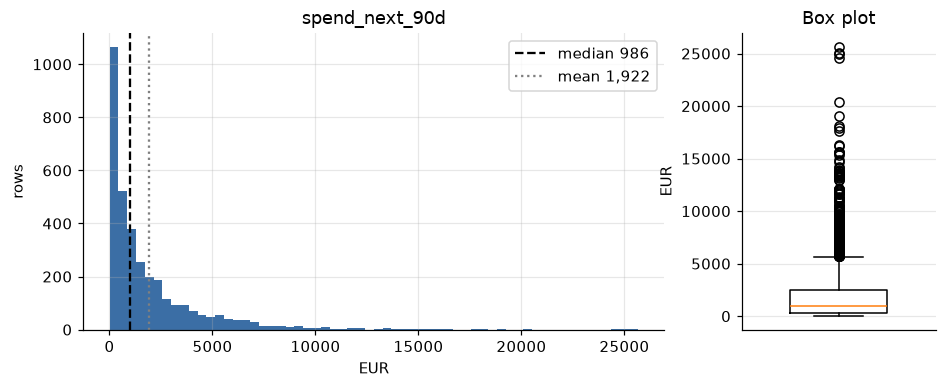

In [8]:
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [3, 1]})
ax_hist.hist(spend, bins=60, color=COLOR)
ax_hist.axvline(spend.median(), color="black", linestyle="--", label=f"median {spend.median():,.0f}")
ax_hist.axvline(spend.mean(), color="grey", linestyle=":", label=f"mean {spend.mean():,.0f}")
ax_hist.set(title="spend_next_90d", xlabel="EUR", ylabel="rows")
ax_hist.legend()
ax_box.boxplot(spend, widths=0.5)
ax_box.set(title="Box plot", ylabel="EUR", xticks=[])
plt.show()

In [9]:
bins = [0, 1000, 2000, 3000, 5000, 10000, spend.max()]
binned = pd.cut(spend, bins).value_counts().sort_index()
pd.DataFrame({"rows": binned, "share": (binned / len(spend)).round(3),
              "cumulative share": (binned.cumsum() / len(spend)).round(3)})

,rows,share,cumulative share
spend_next_90d,,,
"(0.0, 1000.0]",1727,0.504,0.504
"(1000.0, 2000.0]",641,0.187,0.691
"(2000.0, 3000.0]",360,0.105,0.796
"(3000.0, 5000.0]",343,0.100,0.897
"(5000.0, 10000.0]",289,0.084,0.981
"(10000.0, 25654.33]",65,0.019,1.000


Half of the returning customers spend under about 1,000 EUR in the next 90 days, but a few spend up to
25,654 EUR. The mean is about twice the median, and many points sit above the upper whisker of the
box plot: the distribution has a long right tail.

### 1.5 The extremes

Are the largest and smallest values plausible, or do they look like errors (a repeated value, a cap,
zeros)?

In [10]:
q1, q3 = spend.quantile([0.25, 0.75])
pd.Series({
    "largest 5": spend.nlargest(5).round(2).tolist(),
    "smallest 5": spend.nsmallest(5).round(2).tolist(),
    "above Q3 + 3 IQR": int((spend > q3 + 3 * (q3 - q1)).sum()),
    "below 10 EUR": int((spend < 10).sum()),
    "zero or negative": int((spend <= 0).sum()),
}).to_frame("value")

,value
largest 5,"[25654.33, 25035.85, 24997.81, 24564.56, 20358..."
smallest 5,"[1.27, 1.33, 1.69, 1.98, 2.32]"
above Q3 + 3 IQR,88
below 10 EUR,25
zero or negative,0


The largest values are all different, so they do not look like a placeholder or a cap. There are no
zeros or negatives. The very high and very low amounts look like real customers, not data errors.

### Summary

- `repeat_purchase_90d`: about 56/44, stable over the years.
- `spend_next_90d`: only for returning customers, 229 of them without a value.
- Spend has a long right tail (median 986, mean 1,922, max 25,654) and no invalid values.